<a href="https://colab.research.google.com/github/suhailabdulwasi/ds2002-fa26/blob/main/notebooks/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [11]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

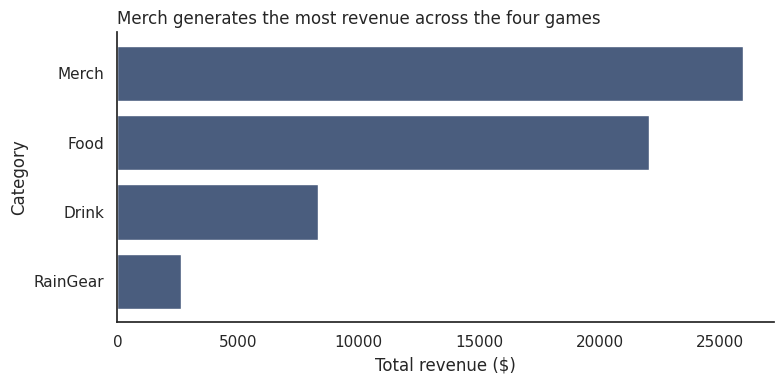

In [12]:
category_revenue = (
    df.groupby('category')['revenue'].sum().sort_values()
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(category_revenue.index, category_revenue.values, color=BLUE)
ax.set_xlim(left=0)

finish(
    ax,
    'Merch generates the most revenue across the four games',
    xlabel='Total revenue ($)',
    ylabel='Category'
)
plt.show()

Caption: Prioritize merchandise inventory because it generates the most revenue in this sample.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

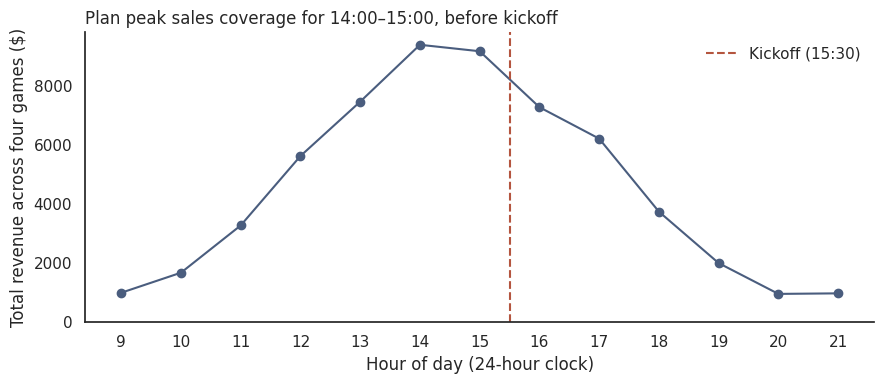

In [13]:
hourly_revenue = df.groupby('hour')['revenue'].sum().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    hourly_revenue.index, hourly_revenue.values,
    color=BLUE, marker='o'
)
ax.axvline(
    15.5, color=RUST, linestyle='--',
    label='Kickoff (15:30)'
)
ax.set_xticks(hourly_revenue.index)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)

finish(
    ax,
    'Plan peak sales coverage for 14:00–15:00, before kickoff',
    xlabel='Hour of day (24-hour clock)',
    ylabel='Total revenue across four games ($)'
)
plt.show()

**Caption:** Schedule strong sales coverage before kickoff, when hourly revenue is highest; check order counts before setting exact staffing levels.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

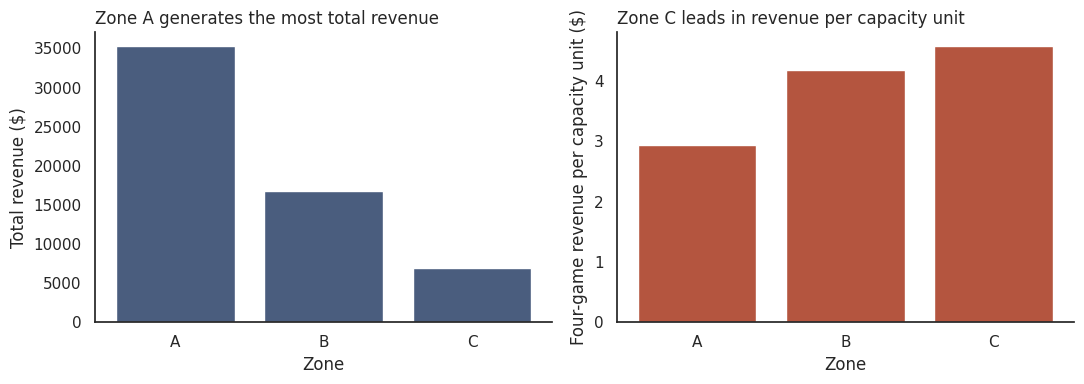

In [14]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
zone_revenue = (
    df.groupby('zone')['revenue'].sum().reindex(['A', 'B', 'C'])
)
capacity = pd.Series(zone_capacity).reindex(zone_revenue.index)
revenue_per_capacity = zone_revenue / capacity

fig, axes = plt.subplots(figsize=(11, 4), ncols=2)

axes[0].bar(zone_revenue.index, zone_revenue.values, color=BLUE)
axes[0].set_ylim(bottom=0)
finish(
    axes[0],
    'Zone A generates the most total revenue',
    xlabel='Zone',
    ylabel='Total revenue ($)'
)

axes[1].bar(
    revenue_per_capacity.index,
    revenue_per_capacity.values,
    color=RUST
)
axes[1].set_ylim(bottom=0)
finish(
    axes[1],
    'Zone C leads in revenue per capacity unit',
    xlabel='Zone',
    ylabel='Four-game revenue per capacity unit ($)'
)

fig.tight_layout()
plt.show()

**Caption, and which panel I would present:** Present total revenue to identify where the most sales dollars come from, and revenue per capacity unit to compare zones relative to their size. I would show a manager the normalized panel when comparing zone performance.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

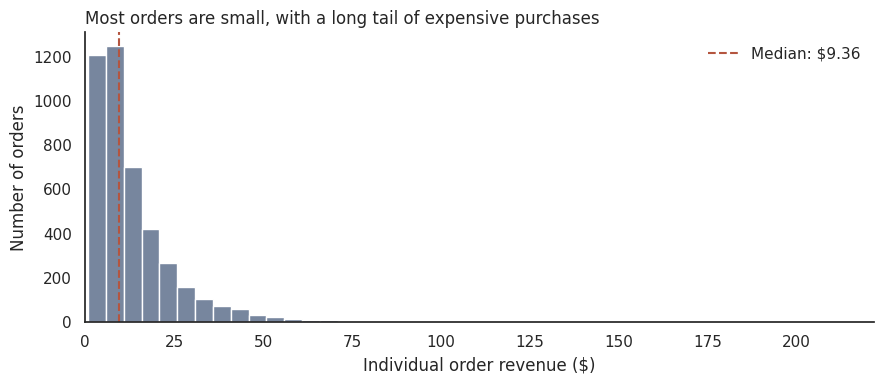

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))

sns.histplot(
    data=df, x='revenue',
    binwidth=5, color=BLUE, ax=ax
)

median_revenue = df['revenue'].median()
ax.axvline(
    median_revenue, color=RUST, linestyle='--',
    label=f'Median: ${median_revenue:.2f}'
)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)

finish(
    ax,
    'Most orders are small, with a long tail of expensive purchases',
    xlabel='Individual order revenue ($)',
    ylabel='Number of orders'
)
plt.show()

**Caption:** Use the $9.36 median as a reference for a typical purchase, since a smaller number of expensive orders pull the mean up to 13.50 dollars.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

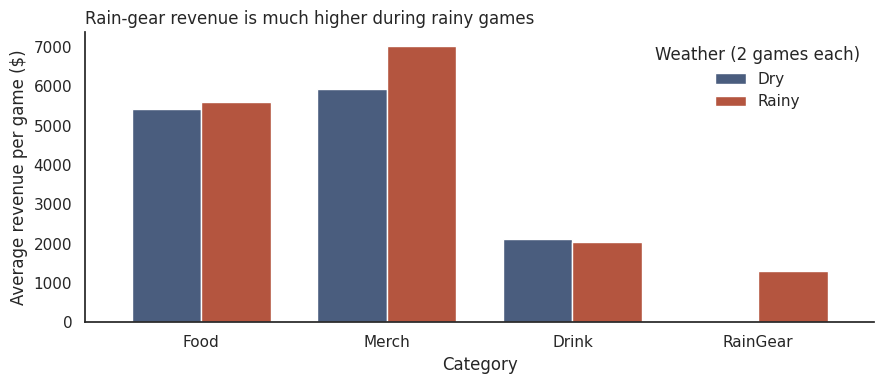

In [16]:
weather_order = ['dry', 'rain']

game_counts = (
    df[['game', 'weather']]
    .drop_duplicates()
    .groupby('weather')
    .size()
)

weather_revenue = (
    df.groupby(['category', 'weather'])['revenue']
    .sum()
    .unstack(fill_value=0)
    .reindex(
        index=['Food', 'Merch', 'Drink', 'RainGear'],
        columns=weather_order
    )
)

per_game = weather_revenue.div(game_counts, axis='columns')

fig, ax = plt.subplots(figsize=(9, 4))
per_game.plot.bar(
    ax=ax, color=[BLUE, RUST],
    rot=0, width=0.75
)
ax.set_ylim(bottom=0)
ax.legend(
    title='Weather (2 games each)',
    labels=['Dry', 'Rainy'],
    frameon=False
)

finish(
    ax,
    'Rain-gear revenue is much higher during rainy games',
    xlabel='Category',
    ylabel='Average revenue per game ($)'
)
plt.show()

**Caption:** Stock more rain gear when rain is forecast, while treating this four-game sample as preliminary evidence.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [17]:
scores = {
    'chart 1 (category)': 6,
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}
for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) Chart 3 changed my impression of the zones. At first, Zone A looked strongest because it had the highest total revenue. After adjusting for capacity, Zone C ranked highest at $4.58 per capacity unit, compared with Zone A’s $2.94. This showed me why total revenue alone can be misleading when comparing zones of different sizes.

b) Total revenue answers which zone contributes the most sales dollars. Revenue per capacity unit answers which zone generates more revenue relative to its size. Capacity is not actual attendance, so the normalized measure does not tell us spending per customer.